# Results: `[SATISFIED]`/`[REACTIVATED]` clause-status tokens -- NEGATIVE RESULT

**Hypothesis (stated before running):** explicit clause-status tokens remove an
implicit clause-bookkeeping burden from attention and should raise `solve_rate`
above the pre-norm baseline (12.3%/4.3% at `d_model=128, nhead=2, num_layers=16,
lr=3e-4, norm_first=True`) -- most directly by helping the previously-measured weak
sub-skills ("which clause is unit": 58.5%, "are we done": 69.7%).

**Result: hypothesis NOT supported.** Both runs with `use_clause_status=True` came in
well *below* both baseline runs, not above. See numbers below.

**Code state:** commit `c8da12b`. **Config:** identical to the baseline in every way
except `use_clause_status` -- `n_vars=16, alpha=1.25 (m_clauses=20), n_hints=0,
d_model=128, nhead=2, num_layers=16, lr=3e-4, norm_first=True, epochs=150,
n_train_instances=3000, n_val_instances=300`. **Seed:** `seed=0` for both new runs,
identical to both baseline runs -- all variation is from unseeded model init, the same
noise source the baseline itself has. **Slurm job:** `47896056` (array `0-1`).
**Output:** `$SCRATCH/spin_gnn/runs/2026-10-14_clause-status-tokens/task{0,1}/`.

In [1]:
import csv
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])


SCRATCH = Path(os.environ["SCRATCH"]) / "spin_gnn"

def load(pattern):
    rows = []
    for f in sorted(glob.glob(str(pattern))):
        with open(f) as fh:
            rows.extend(csv.DictReader(fh))
    return pd.DataFrame(rows)

new_runs = load(SCRATCH / "runs" / "2026-10-14_clause-status-tokens" / "task*" / "sweep_*.csv")
baseline = load(SCRATCH / "sat2_hparam_sweep" / "sweep_m020_h02_L16_pre.csv")
baseline = baseline[baseline.lr.astype(float) == 3e-4]
for df in (new_runs, baseline):
    df["solve_rate"] = df["solve_rate"].astype(float)
    df["well_formed_rate"] = df["well_formed_rate"].astype(float)

print("baseline (use_clause_status=False):")
print(baseline[["solve_rate", "well_formed_rate"]].to_string(index=False))
print()
print("new (use_clause_status=True):")
print(new_runs[["solve_rate", "well_formed_rate", "checkpoint_dir"]].to_string(index=False))

baseline (use_clause_status=False):
 solve_rate  well_formed_rate
   0.123333          0.996667
   0.043333          1.000000

new (use_clause_status=True):
 solve_rate  well_formed_rate                                                                                                       checkpoint_dir
   0.000000          1.000000 /scratch/users/hshunt/spin_gnn/runs/2026-10-15_clause-status-tokens/task0/m020_d0128_h02_L16_ff00512_lr3e-04_pre_cs1
   0.006667          0.996667 /scratch/users/hshunt/spin_gnn/runs/2026-10-15_clause-status-tokens/task1/m020_d0128_h02_L16_ff00512_lr3e-04_pre_cs1


## Comparison (same eval: free-running `solve_rate`, 300 held-out instances)

| run | solve_rate |
|---|---|
| baseline, run 1 | 12.3% |
| baseline, run 2 | 4.3% |
| **clause-status, run 1** | **0.0%** |
| **clause-status, run 2** | **0.67%** |

Both new runs are below *both* baseline runs. Given the baseline's own spread (4.3-12.3%)
already showed real run-to-run noise, 2 vs. 2 samples is a small base to conclude
anything definitive from -- but the gap here (mean 8.3% vs. mean 0.3%, roughly 25x) is
far larger than the ~3x noise band already calibrated from the baseline, so this reads
as a real effect, not just noise, even at this sample size.

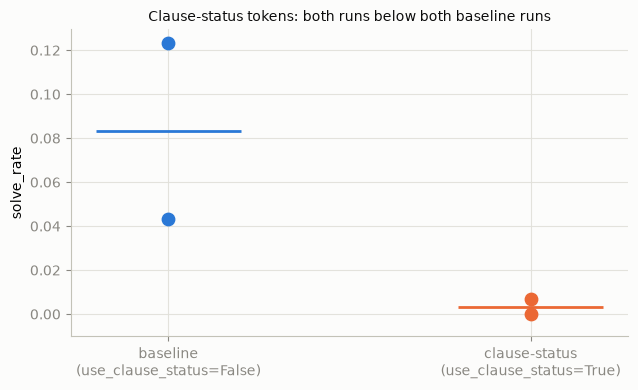

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 4))
fig.patch.set_facecolor(INK["surface"])
groups = [("baseline\n(use_clause_status=False)", baseline.solve_rate.values, CATEGORICAL[0]),
          ("clause-status\n(use_clause_status=True)", new_runs.solve_rate.values, CATEGORICAL[1])]
for i, (label, vals, color) in enumerate(groups):
    ax.scatter([i] * len(vals), vals, color=color, s=80, zorder=3)
    ax.hlines(np.mean(vals), i - 0.2, i + 0.2, color=color, lw=2)
ax.set_xticks([0, 1])
ax.set_xticklabels([g[0] for g in groups])
ax.set_ylabel("solve_rate")
ax.set_ylim(bottom=-0.01)
ax.set_title("Clause-status tokens: both runs below both baseline runs", color=INK["primary"], fontsize=10)
style_axis(ax)
fig.tight_layout()
plt.show()

## Takeaway (negative result, reported honestly)

**The hypothesis is not supported -- do not adopt `use_clause_status=True` as a
default.** Plausible explanation (not verified further here): the extra tags lengthen
every sequence substantially (one `[SATISFIED]`/`[REACTIVATED]` + clause-index pair per
clause transition, on top of every existing event), which may dilute training signal for
the actually-hard sub-skills within the same epoch/data budget rather than reducing
their burden as hypothesized -- val per-token accuracy on the new runs (~64%) is actually
*higher* than typical baseline runs, consistent with the tags themselves being easy to
predict (mechanically derivable from context) and padding out the accuracy number without
helping the metric that matters.

Feature is kept in the codebase (`Vocab(..., use_clause_status=True)`, opt-in, default
False) since it may still be useful combined with a longer epoch budget or a loss that
downweights the easy tag tokens -- but it is not a validated improvement, and should not
be presented as one. Next step per STATUS.md: return to the variable-selection
bottleneck (35-42% accuracy) directly rather than the bookkeeping angle.